Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    roc_auc_score
)
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

c:\Users\jason\Desktop\flight delay\.venv\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Loading

In [2]:
DATA_DIR = Path.cwd() / "data" / "raw"

AIRPORTS_3 = ["LAX", "ORD", "JFK"]
AIRPORTS_5 = ["LAX", "ORD", "JFK", "ATL", "DFW"]
AIRPORTS_8 = ["LAX", "ORD", "JFK", "ATL", "DFW", "SEA", "DEN", "MIA"]

In [3]:
def load_airports(airport_codes):
    dfs = []
    
    for airport in airport_codes:
        path = DATA_DIR / f"{airport}.csv"
        df = pd.read_csv(path)
        df["AirportFile"] = airport
        dfs.append(df)
    
    return pd.concat(dfs, ignore_index=True)

In [4]:
# Load the raw flight data (use all 8 airports as the main dataset)
flights = load_airports(AIRPORTS_8)
print("Loaded raw flights:", flights.shape)
flights.head()

Loaded raw flights: (5975503, 23)


,Time,Origin,Dest,Carrier,Cancelled,CancellationReason,Delayed,DepDelayMinutes,CarrierDelay,WeatherDelay,...,Temperature,Feels_Like_Temperature,Altimeter_Pressure,Sea_Level_Pressure,Visibility,Wind_Speed,Wind_Gust,Precipitation,Ice_Accretion_3hr,AirportFile
0,2021-01-01 09:00:00,LAX,JFK,American Airlines Inc.,False,NaN,False,0.0,NaN,NaN,...,56.0,55.9,1020.32,1020.1,16093.40,0.0,24.97,0.0,0.0,LAX
1,2021-01-02 09:00:00,LAX,JFK,American Airlines Inc.,False,NaN,True,2.0,NaN,NaN,...,54.0,54.0,1025.74,1025.5,16093.40,0.0,24.97,0.0,0.0,LAX
2,2021-01-03 09:00:00,LAX,JFK,American Airlines Inc.,False,NaN,True,28.0,28.0,0.0,...,52.0,52.0,1024.38,1015.2,4828.02,4.6,24.97,0.0,0.0,LAX
3,2021-01-03 09:00:00,LAX,JFK,American Airlines Inc.,False,NaN,True,28.0,28.0,0.0,...,53.0,53.1,1024.38,1024.1,6437.36,4.6,24.97,0.0,0.0,LAX
4,2021-01-04 09:00:00,LAX,JFK,American Airlines Inc.,False,NaN,False,0.0,NaN,NaN,...,51.0,51.1,1023.03,1015.2,6437.36,4.6,24.97,0.0,0.0,LAX


Preprocessing

In [5]:
def get_season(month):
    if month in [12, 1, 2]:
        return "winter"
    elif month in [3, 4, 5]:
        return "spring"
    elif month in [6, 7, 8]:
        return "summer"
    else:
        return "fall"


def get_time_of_day(hour):
    if 5 <= hour < 12:
        return "morning"
    elif 12 <= hour < 17:
        return "afternoon"
    elif 17 <= hour < 22:
        return "evening"
    else:
        return "night"


def preprocess_flights(flights):
    flights = flights.copy()

    # Convert cancelled/delayed to clean true/false strings
    flights["Cancelled"] = flights["Cancelled"].astype(str).str.lower()
    flights["Delayed"] = flights["Delayed"].astype(str).str.lower()

    # Remove cancelled flights because cancellation is a different problem
    flights = flights[flights["Cancelled"] == "false"].copy()

    # Convert time
    flights["Time"] = pd.to_datetime(flights["Time"], errors="coerce")
    flights = flights.dropna(subset=["Time"])

    # Time features
    flights["Date"] = flights["Time"].dt.date
    flights["Month"] = flights["Time"].dt.month
    flights["DayOfWeek"] = flights["Time"].dt.dayofweek
    flights["DepHour"] = flights["Time"].dt.hour
    flights["Season"] = flights["Month"].apply(get_season)
    flights["TimeOfDay"] = flights["DepHour"].apply(get_time_of_day)

    # Airport congestion = flights from same origin on same date/hour
    flights["AirportCongestionCount"] = (
        flights
        .groupby(["Origin", "Date", "DepHour"])["Origin"]
        .transform("count")
    )

    # Rank avoids qcut errors from duplicate values
    flights["AirportCongestion"] = pd.qcut(
        flights["AirportCongestionCount"].rank(method="first"),
        q=3,
        labels=["low", "medium", "high"]
    )

    return flights



In [6]:
flights_clean = preprocess_flights(flights)
flights_clean.head()

,Time,Origin,Dest,Carrier,Cancelled,CancellationReason,Delayed,DepDelayMinutes,CarrierDelay,WeatherDelay,...,Ice_Accretion_3hr,AirportFile,Date,Month,DayOfWeek,DepHour,Season,TimeOfDay,AirportCongestionCount,AirportCongestion
0,2021-01-01 09:00:00,LAX,JFK,American Airlines Inc.,false,NaN,false,0.0,NaN,NaN,...,0.0,LAX,2021-01-01,1,4,9,winter,morning,25,low
1,2021-01-02 09:00:00,LAX,JFK,American Airlines Inc.,false,NaN,true,2.0,NaN,NaN,...,0.0,LAX,2021-01-02,1,5,9,winter,morning,28,low
2,2021-01-03 09:00:00,LAX,JFK,American Airlines Inc.,false,NaN,true,28.0,28.0,0.0,...,0.0,LAX,2021-01-03,1,6,9,winter,morning,68,high
3,2021-01-03 09:00:00,LAX,JFK,American Airlines Inc.,false,NaN,true,28.0,28.0,0.0,...,0.0,LAX,2021-01-03,1,6,9,winter,morning,68,high
4,2021-01-04 09:00:00,LAX,JFK,American Airlines Inc.,false,NaN,false,0.0,NaN,NaN,...,0.0,LAX,2021-01-04,1,0,9,winter,morning,90,high


Add Weather Category

In [7]:
def add_weather_categories(flights):
    flights = flights.copy()

    flights["TemperatureCategory"] = pd.qcut(
        flights["Temperature"].rank(method="first"),
        q=3,
        labels=["low", "medium", "high"]
    )

    flights["VisibilityCategory"] = pd.qcut(
        flights["Visibility"].rank(method="first"),
        q=3,
        labels=["low", "medium", "high"]
    )

    flights["WindCategory"] = pd.qcut(
        flights["Wind_Speed"].rank(method="first"),
        q=3,
        labels=["low", "medium", "high"]
    )

    flights["PrecipitationCategory"] = np.where(
        flights["Precipitation"] > 0,
        "some",
        "none"
    )

    flights["IceCategory"] = np.where(
        flights["Ice_Accretion_3hr"] > 0,
        "some",
        "none"
    )

    return flights

In [8]:
flights_clean = add_weather_categories(flights_clean)

In [9]:
def make_model_data(flights, columns, sample_size=200000):
    data = flights[columns].dropna().copy()

    if len(data) > sample_size:
        data = data.sample(n=sample_size, random_state=42)

    data = data.reset_index(drop=True)

    for col in data.columns:
        data[col] = data[col].astype(str)

    return data

Main function to train and evaluate

In [10]:
def train_and_evaluate(model_name, data, edges, test_sample_size=10000):
    train_data, test_data = train_test_split(
        data,
        test_size=0.2,
        random_state=42,
        stratify=data["Delayed"]
    )

    model = DiscreteBayesianNetwork(edges)
    model.fit(train_data)

    infer = VariableElimination(model)

    if len(test_data) > test_sample_size:
        test_sample = test_data.sample(n=test_sample_size, random_state=42)
    else:
        test_sample = test_data

    pred_probs = []
    true_labels = []

    for _, row in test_sample.iterrows():
        evidence = row.drop("Delayed").to_dict()

        try:
            result = infer.query(
                variables=["Delayed"],
                evidence=evidence,
                show_progress=False
            )

            delayed_states = result.state_names["Delayed"]
            true_index = delayed_states.index("true")
            prob_delay = result.values[true_index]

            pred_probs.append(prob_delay)
            true_labels.append(1 if row["Delayed"] == "true" else 0)

        except Exception:
            continue

    pred_labels = [1 if p >= 0.5 else 0 for p in pred_probs]

    return {
        "Model": model_name,
        "Rows": len(data),
        "Evaluated": len(true_labels),
        "Accuracy": accuracy_score(true_labels, pred_labels),
        "Precision": precision_score(true_labels, pred_labels, zero_division=0),
        "Recall": recall_score(true_labels, pred_labels, zero_division=0),
        "F1": f1_score(true_labels, pred_labels, zero_division=0),
        "Brier": brier_score_loss(true_labels, pred_probs),
        "AUC": roc_auc_score(true_labels, pred_probs)
    }

Model 1 Basic

In [11]:
basic_cols = [
    "Season",
    "DayOfWeek",
    "TimeOfDay",
    "Origin",
    "Carrier",
    "Delayed"
]

basic_edges = [
    ("Season", "Delayed"),
    ("DayOfWeek", "Delayed"),
    ("TimeOfDay", "Delayed"),
    ("Origin", "Delayed"),
    ("Carrier", "Delayed")
]

Model 2 Add congestion

In [12]:
congestion_cols = [
    "Season",
    "DayOfWeek",
    "TimeOfDay",
    "Origin",
    "Carrier",
    "AirportCongestion",
    "Delayed"
]

congestion_edges = [
    ("Season", "Delayed"),
    ("DayOfWeek", "Delayed"),
    ("TimeOfDay", "AirportCongestion"),
    ("Origin", "AirportCongestion"),
    ("AirportCongestion", "Delayed"),
    ("Origin", "Delayed"),
    ("Carrier", "Delayed")
]

Model 3 Add weather

In [13]:
weather_cols = [
    "Season",
    "DayOfWeek",
    "TimeOfDay",
    "Origin",
    "Carrier",
    "AirportCongestion",
    "TemperatureCategory",
    "VisibilityCategory",
    "WindCategory",
    "PrecipitationCategory",
    "IceCategory",
    "Delayed"
]

weather_edges = [
    ("Season", "TemperatureCategory"),
    ("Season", "PrecipitationCategory"),
    ("Season", "IceCategory"),

    ("TimeOfDay", "AirportCongestion"),
    ("Origin", "AirportCongestion"),

    ("Season", "Delayed"),
    ("DayOfWeek", "Delayed"),
    ("TimeOfDay", "Delayed"),
    ("Origin", "Delayed"),
    ("Carrier", "Delayed"),
    ("AirportCongestion", "Delayed"),

    ("TemperatureCategory", "Delayed"),
    ("VisibilityCategory", "Delayed"),
    ("WindCategory", "Delayed"),
    ("PrecipitationCategory", "Delayed"),
    ("IceCategory", "Delayed")
]

Run all experiments

In [14]:
results = []

basic_data = make_model_data(flights_clean, basic_cols)
results.append(train_and_evaluate("Basic BN", basic_data, basic_edges))

congestion_data = make_model_data(flights_clean, congestion_cols)
results.append(train_and_evaluate("BN + Congestion", congestion_data, congestion_edges))

weather_data = make_model_data(flights_clean, weather_cols)
results.append(train_and_evaluate("BN + Congestion + Weather", weather_data, weather_edges))

results_df = pd.DataFrame(results)

# Baseline: always predict "not delayed"
baseline_data = make_model_data(flights_clean, basic_cols)
y = baseline_data["Delayed"].apply(lambda x: 1 if x == "true" else 0)

baseline_row = {
    "Model": "Baseline: always not delayed",
    "Rows": len(baseline_data),
    "Evaluated": len(baseline_data),
    "Accuracy": (y == 0).mean(),
    "Precision": 0.0,
    "Recall": 0.0,
    "F1": 0.0,
    "Brier": y.mean(),       # predicting P(delay)=0 for everyone
    "AUC": 0.5               # no discrimination
}

results_df = pd.concat(
    [pd.DataFrame([baseline_row]), results_df],
    ignore_index=True
)

# tidy column order
results_df = results_df[["Model","Rows","Evaluated","Accuracy","Precision","Recall","F1","Brier","AUC"]]
results_df

,Model,Rows,Evaluated,Accuracy,Precision,Recall,F1,Brier,AUC
0,Baseline: always not delayed,200000,200000,0.595875,0.000000,0.000000,0.000000,0.404125,0.500000
1,Basic BN,200000,10000,0.636600,0.562434,0.402907,0.469489,0.229699,0.645344
2,BN + Congestion,200000,10000,0.618400,0.532932,0.354798,0.425993,0.233794,0.622998
3,BN + Congestion + Weather,200000,10000,0.557700,0.460541,0.631671,0.532699,0.272329,0.605816


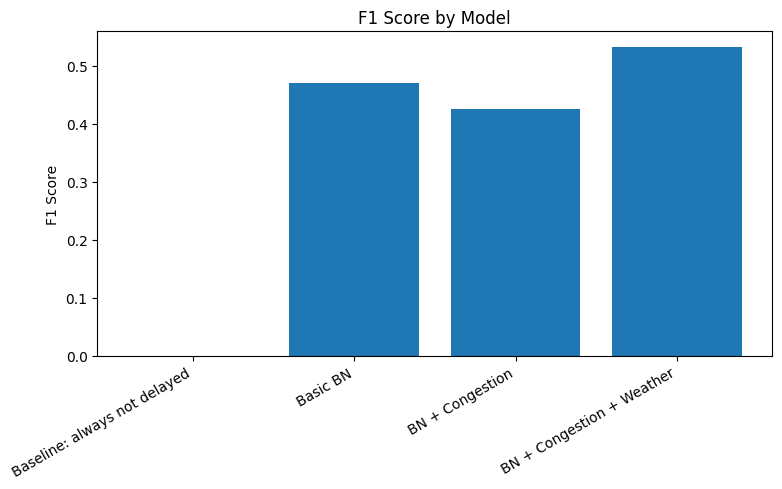

In [15]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["F1"])
plt.ylabel("F1 Score")
plt.title("F1 Score by Model")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("outputs/f1_by_model.png")
plt.show()

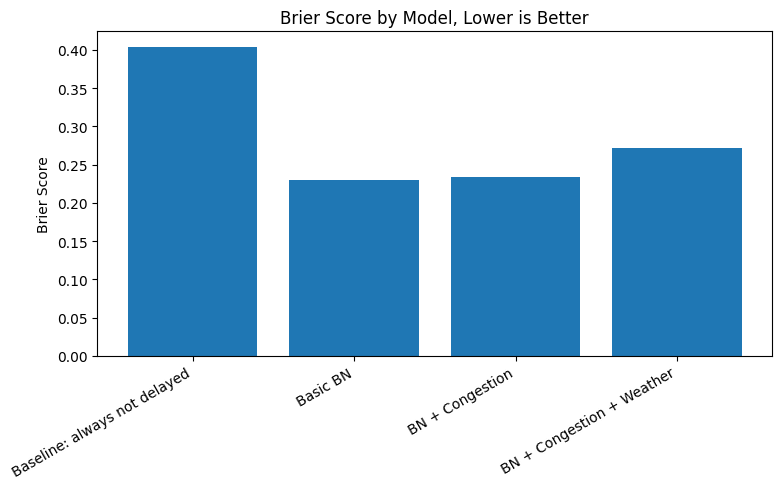

In [16]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Brier"])
plt.ylabel("Brier Score")
plt.title("Brier Score by Model, Lower is Better")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("outputs/brier_by_model.png")
plt.show()

In [17]:
# Experiment 2: How does performance change with more training data?
# We hold the model fixed (BN + Congestion) and vary the training set size.
import time

def train_and_evaluate_sized(model_name, full_data, edges, train_size, test_sample_size=10000):
    # stratified split first, then subsample the TRAIN set to train_size
    train_data, test_data = train_test_split(
        full_data, test_size=0.2, random_state=42, stratify=full_data["Delayed"]
    )
    if len(train_data) > train_size:
        train_data = train_data.sample(n=train_size, random_state=42)

    model = DiscreteBayesianNetwork(edges)
    start = time.time()
    model.fit(train_data)
    train_time = time.time() - start

    infer = VariableElimination(model)
    if len(test_data) > test_sample_size:
        test_data = test_data.sample(n=test_sample_size, random_state=42)

    pred_probs, true_labels = [], []
    for _, row in test_data.iterrows():
        evidence = row.drop("Delayed").to_dict()
        try:
            result = infer.query(variables=["Delayed"], evidence=evidence, show_progress=False)
            ti = result.state_names["Delayed"].index("true")
            pred_probs.append(result.values[ti])
            true_labels.append(1 if row["Delayed"] == "true" else 0)
        except Exception:
            continue

    pred_labels = [1 if p >= 0.5 else 0 for p in pred_probs]
    return {
        "TrainSize": len(train_data),
        "Accuracy": accuracy_score(true_labels, pred_labels),
        "F1": f1_score(true_labels, pred_labels, zero_division=0),
        "Brier": brier_score_loss(true_labels, pred_probs),
        "AUC": roc_auc_score(true_labels, pred_probs),
        "TrainTimeSec": round(train_time, 3)
    }

# Use the full congestion dataset (all 8 airports already in flights_clean)
full_congestion_data = make_model_data(flights_clean, congestion_cols, sample_size=10**9)
print("Total available rows:", len(full_congestion_data))

train_sizes = [1000, 5000, 20000, 50000, 100000]
size_results = []
for ts in train_sizes:
    if ts <= int(len(full_congestion_data) * 0.8):
        size_results.append(
            train_and_evaluate_sized("BN + Congestion", full_congestion_data, congestion_edges, ts)
        )

size_df = pd.DataFrame(size_results)
size_df

Total available rows: 5843510


,TrainSize,Accuracy,F1,Brier,AUC,TrainTimeSec
0,1000,0.4597,0.548433,0.303076,0.524982,0.072
1,5000,0.5100,0.512922,0.312716,0.545416,0.063
2,20000,0.5692,0.478450,0.268536,0.580701,0.063
3,50000,0.6011,0.453037,0.248193,0.604187,0.092
4,100000,0.6226,0.450975,0.235805,0.626105,0.137


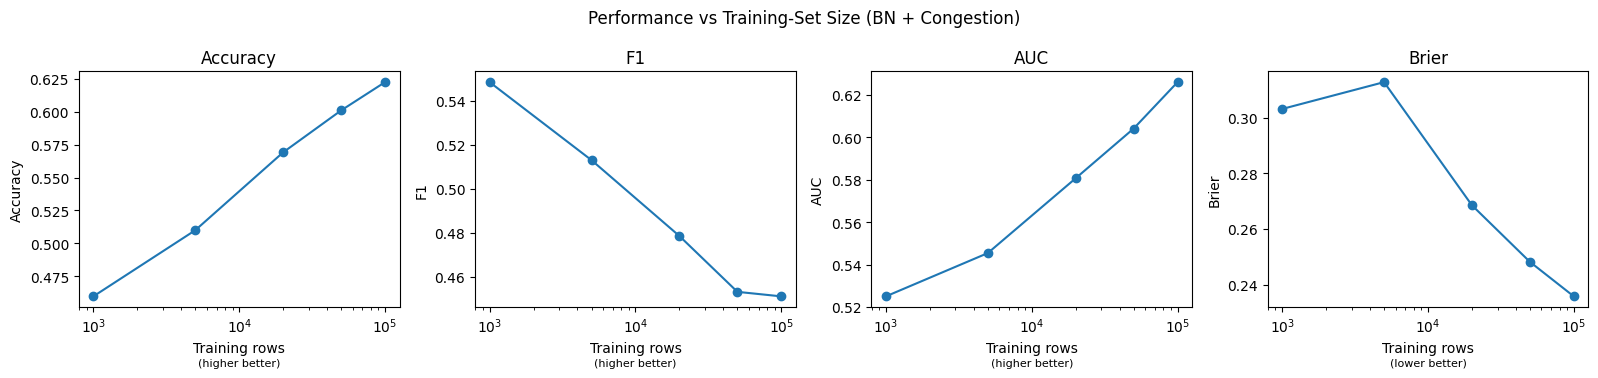

In [18]:
# Plot: performance vs training-set size
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, metric in zip(axes, ["Accuracy", "F1", "AUC", "Brier"]):
    ax.plot(size_df["TrainSize"], size_df[metric], marker="o")
    ax.set_title(metric)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(metric)
    ax.set_xscale("log")
    better = "lower better" if metric == "Brier" else "higher better"
    ax.text(0.5, -0.25, f"({better})", transform=ax.transAxes, ha="center", fontsize=8)

plt.suptitle("Performance vs Training-Set Size (BN + Congestion)")
plt.tight_layout()
plt.savefig("outputs/training_size_experiment.png", dpi=150, bbox_inches="tight")
plt.show()

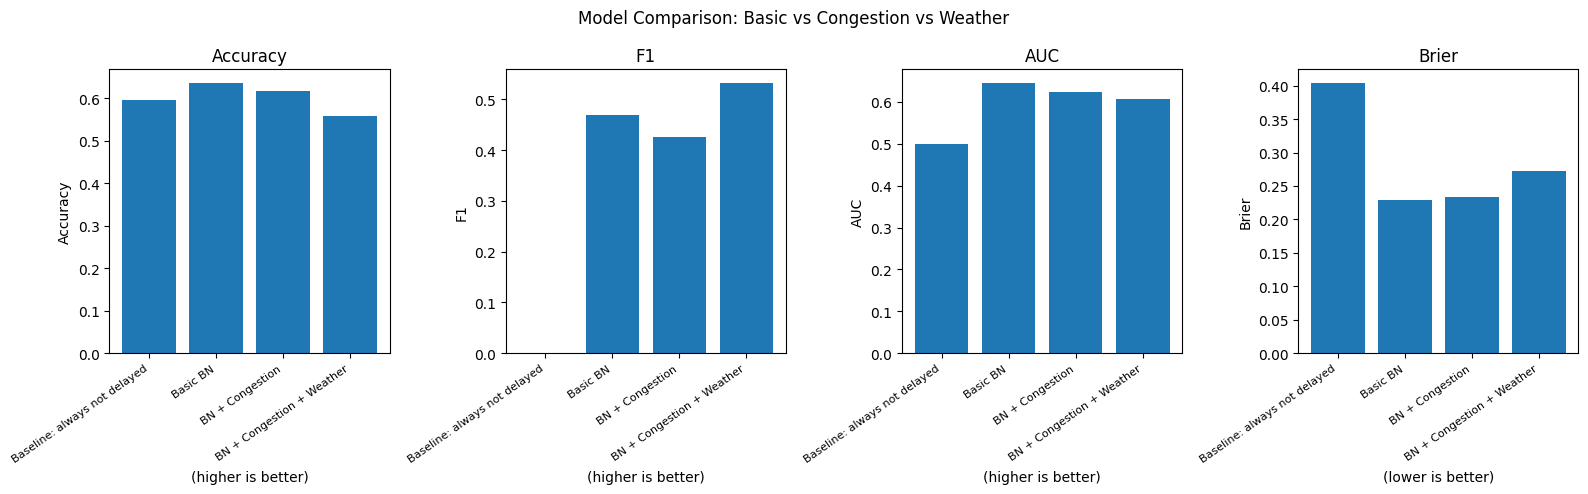

In [19]:
metrics = ["Accuracy", "F1", "AUC", "Brier"]
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, metric in zip(axes, metrics):
    bars = ax.bar(results_df["Model"], results_df[metric])
    ax.set_title(metric)
    ax.set_ylabel(metric)
    ax.set_xticks(range(len(results_df["Model"])))
    ax.set_xticklabels(results_df["Model"], rotation=35, ha="right", fontsize=8)
    better = "lower" if metric == "Brier" else "higher"
    ax.set_xlabel(f"({better} is better)")

plt.suptitle("Model Comparison: Basic vs Congestion vs Weather")
plt.tight_layout()
plt.savefig("outputs/model_comparison.png")
plt.show()